# EDA: order data for the Discount & Margin Dashboard

Quick exploratory analysis (shape, types, missing values, distributions, relationships) used to decide what goes on the dashboard. Team: **Jiacheng Xu**.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

df = pd.read_csv('order_data.csv', parse_dates=['order_date'])
print(df.shape)
df.head()

(5000, 14)


,order_date,year,market,region,category,sub_category,segment,ship_mode,order_priority,sales,quantity,discount,profit,shipping_cost
0,2018-09-06,2018,US,Central,Furniture,Chairs,Home Office,Second Class,Critical,412.372111,4,0.25,68.524422,13.95
1,2017-10-22,2017,LATAM,South,Furniture,Tables,Consumer,Standard Class,Low,571.817358,6,0.05,93.213472,21.15
2,2020-03-15,2020,LATAM,Central,Technology,Copiers,Home Office,First Class,High,336.067842,2,0.02,49.193568,18.02
3,2017-12-26,2017,EMEA,South,Office Supplies,Art,Corporate,Same Day,Medium,347.199988,5,0.35,61.229998,8.21
4,2020-06-04,2020,LATAM,East,Furniture,Tables,Corporate,Second Class,Low,606.644546,6,0.20,75.238909,46.09


## 1. Types and missing values

In [2]:
print(df.dtypes)
print('\nMissing values per column:')
print(df.isna().sum())
print('\nDuplicate rows:', df.duplicated().sum())
print('Period:', df['order_date'].min().date(), 'to', df['order_date'].max().date())

order_date        datetime64[us]
year                       int64
market                       str
region                       str
category                     str
sub_category                 str
segment                      str
ship_mode                    str
order_priority               str
sales                    float64
quantity                   int64
discount                 float64
profit                   float64
shipping_cost            float64
dtype: object

Missing values per column:
order_date        0
year              0
market            0
region            0
category          0
sub_category      0
segment           0
ship_mode         0
order_priority    0
sales             0
quantity          0
discount          0
profit            0
shipping_cost     0
dtype: int64

Duplicate rows: 0
Period: 2016-01-01 to 2020-12-30


## 2. Distributions

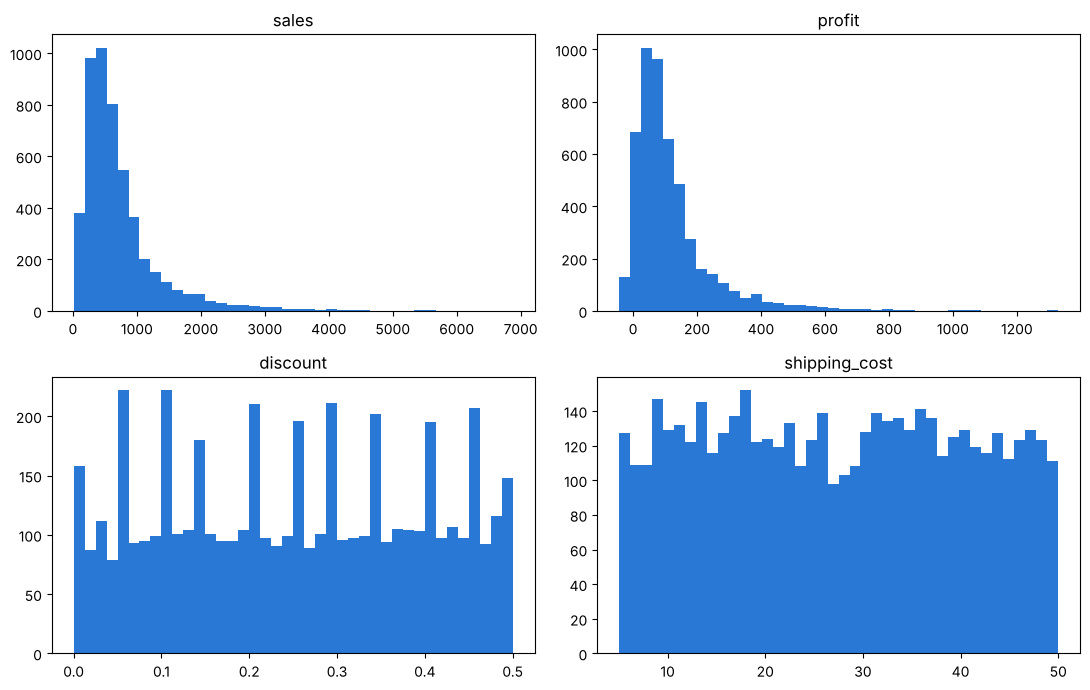

         sales   profit  discount  shipping_cost  quantity
count  5000.00  5000.00   5000.00        5000.00   5000.00
mean    725.68   117.80      0.25          27.33      5.48
std     646.50   129.81      0.14          12.92      2.87
min      10.95   -43.97      0.00           5.02      1.00
25%     336.62    39.69      0.12          16.12      3.00
50%     543.14    81.87      0.25          27.28      5.00
75%     876.45   146.98      0.38          38.39      8.00
max    6875.39  1328.68      0.50          49.98     10.00

Orders with sales over $3,000: 73
Share of loss-making orders: 0.053


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), ['sales', 'profit', 'discount', 'shipping_cost']):
    ax.hist(df[col], bins=40, color='#2a78d6')
    ax.set_title(col)
plt.tight_layout(); plt.show()
print(df[['sales', 'profit', 'discount', 'shipping_cost', 'quantity']].describe().round(2))
print('\nOrders with sales over $3,000:', (df['sales'] > 3000).sum())
print('Share of loss-making orders:', round((df['profit'] < 0).mean(), 3))

Sales are right-skewed (median about \$543, a few orders above \$3,000), while discount and shipping cost look almost perfectly uniform.

In [4]:
print(df.groupby('year').size())
print(df['market'].value_counts())
print(pd.crosstab(df['market'], df['region']))

year
2016    1007
2017     994
2018     997
2019    1014
2020     988
dtype: int64
market
APAC     1279
US       1251
LATAM    1240
EMEA     1230
Name: count, dtype: int64
region  Central  East  South  West
market                            
APAC        323   338    310   308
EMEA        325   295    314   296
LATAM       302   306    318   314
US          319   304    294   334


Orders are split almost exactly evenly across years and markets, and every market has the same four regions (Central, East, South, West), even APAC and EMEA. The region column therefore has no clear business meaning, and the even splits suggest the file may be simulated. Region is left off the dashboard.

## 3. Margin by segment

In [5]:
def margin_table(col):
    g = df.groupby(col).agg(orders=('sales', 'size'), sales=('sales', 'sum'), profit=('profit', 'sum'))
    g['margin_%'] = (g['profit'] / g['sales'] * 100).round(2)
    g[['sales', 'profit']] = g[['sales', 'profit']].round(0)
    return g

print('Overall margin: %.2f%%' % (df['profit'].sum() / df['sales'].sum() * 100))
for col in ['market', 'category', 'segment', 'ship_mode', 'order_priority']:
    print(margin_table(col), '\n')

Overall margin: 16.23%
        orders     sales    profit  margin_%
market                                      
APAC      1279  910307.0  147492.0     16.20
EMEA      1230  915047.0  148356.0     16.21
LATAM     1240  911525.0  149184.0     16.37
US        1251  891535.0  143976.0     16.15 

                 orders      sales    profit  margin_%
category                                              
Furniture          1714  1233164.0  199400.0     16.17
Office Supplies    1643  1200969.0  194725.0     16.21
Technology         1643  1194281.0  194883.0     16.32 

             orders      sales    profit  margin_%
segment                                           
Consumer       1684  1222091.0  198939.0     16.28
Corporate      1657  1205111.0  195075.0     16.19
Home Office    1659  1201212.0  194994.0     16.23 

                orders     sales    profit  margin_%
ship_mode                                           
First Class       1299  923123.0  149225.0     16.17
Same Day    

Profit margin is about 16% in every market, category, segment, ship mode and order priority (all between 16.0% and 16.4%). Breakdowns by these fields would not change any decision, so most of them are cut.

## 4. Discount and margin: the relationship that matters

               orders     sales    profit  margin_%
discount_band                                      
0-10%            1053  952833.0  161931.0     16.99
10-20%            999  766766.0  125521.0     16.37
20-30%            989  686770.0  110823.0     16.14
30-40%           1015  674207.0  107113.0     15.89
Over 40%          944  547838.0   83619.0     15.26


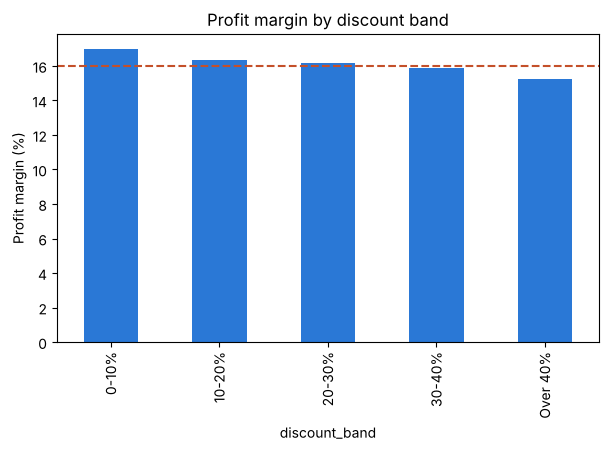

In [6]:
df['discount_band'] = pd.cut(df['discount'], bins=[-0.001, 0.1, 0.2, 0.3, 0.4, 1.0],
                             labels=['0-10%', '10-20%', '20-30%', '30-40%', 'Over 40%'])
band = df.groupby('discount_band', observed=False).agg(orders=('sales', 'size'), sales=('sales', 'sum'), profit=('profit', 'sum'))
band['margin_%'] = (band['profit'] / band['sales'] * 100).round(2)
print(band.assign(sales=band['sales'].round(0), profit=band['profit'].round(0)))
band['margin_%'].plot(kind='bar', color='#2a78d6', figsize=(7, 4), title='Profit margin by discount band')
plt.axhline(16, color='#c4502a', linestyle='--'); plt.ylabel('Profit margin (%)'); plt.show()

Margin falls steadily as the discount deepens, from about 17.0% at 0–10% discount to about 15.3% above 40%. This is the one lever in the data that a manager can actually pull, so it becomes the dashboard's focus.

## 5. Margin over time

count    60.00
mean     16.19
std       0.47
min      14.98
25%      15.85
50%      16.25
75%      16.57
max      17.17
Name: margin_%, dtype: float64


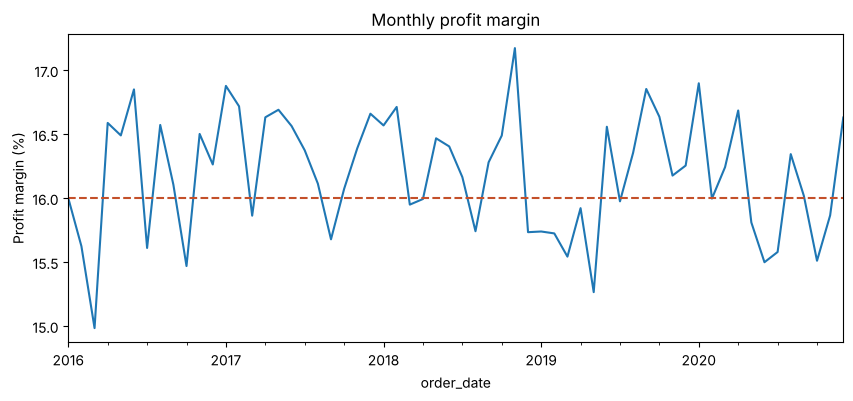

In [7]:
monthly = df.set_index('order_date').resample('MS')[['sales', 'profit']].sum()
monthly['margin_%'] = monthly['profit'] / monthly['sales'] * 100
print(monthly['margin_%'].describe().round(2))
monthly['margin_%'].plot(figsize=(10, 4), title='Monthly profit margin')
plt.axhline(16, color='#c4502a', linestyle='--'); plt.ylabel('Profit margin (%)'); plt.show()

Monthly margin moves between about 15.0% and 17.2% with no clear trend, so the monthly chart is read against the 16% target rather than month to month.